# Sprint 8 · Reto «Duelo de modelos» · Equipo 5 Green
Fecha : 12 - 13.11.2026

**Equipo:** Cristina, Miguel, Fran, Andri y Anzhela · **Cliente:** TurisData (reservas **sintéticas** de un hotel).

Scrum master: Fran, Tecnico :  Anzhela

El gerente pregunta: **¿qué modelo ponemos en producción para predecir cancelaciones?** Este cuaderno enfrenta
8 modelos de 6 familias con **las mismas reglas** (mismos datos, mismos folds, misma métrica), los puntúa con tres
criterios (**rendimiento, explicabilidad y coste**) y elige un campeón.

**Basado en** `S08_06_leaderboard_plantilla`: las celdas de **preparación, datos y herramientas** (1, 2 y 3) están **sin modificar**,
para que todos los equipos midan igual. Todo lo demás son los huecos rellenados y las celdas añadidas por el equipo.

**Cómo ejecutarlo:** *Entorno de ejecución → Reiniciar y ejecutar todo* (≈ 3–5 min en Colab). Semilla: `SEMILLA = 42`.
Se genera `leaderboard_S08.csv` (hay que **descargarlo antes de cerrar Colab**: lo hace la última celda) y `cifras_reto_S08.json`.

**Regla de oro:** `X_test` **no se usa** hasta el apartado 9, y **solo con el campeón, una vez**. Las búsquedas de hiperparámetros
y todos los análisis usan **solo `X_train`** con validación cruzada.

| Apartado | Contenido |
|---|---|
| 1–3 | Preparación, datos y herramientas (de la plantilla, sin cambios) |
| 4 | Baseline y regresión logística (ejercicio 1) |
| 5 | Árbol, bosque, *boosting* y SVM (ejercicio 2) |
| 6 | Búsqueda de hiperparámetros en dos familias (nivel estándar) |
| 7 | Rendimiento frente a explicabilidad y coste |
| 8 | Pesos, puntuación global, campeón y **sensibilidad** (ejercicio 3) |
| 9 | Extras con solo train: incertidumbre (varias semillas), variables importantes, AUC por canal/país |
| 10 | **Examen final en test: solo el campeón, una vez** (ejercicio 4) |
| 11 | Cifras para la *model card* y descarga del CSV |

## 1. Preparación (de la plantilla, sin cambios)

In [ ]:
# Preparación (ejecuta esta celda siempre la primera)
import os, urllib.request

BASE_URL = "https://raw.githubusercontent.com/cCoolBoox/IFCD107-alumnado/main/datos/"

def dato(nombre):
    """Devuelve la ruta local de un archivo de datos del curso (lo descarga si no está)."""
    for carpeta in ("datos", "../datos", "../../datos", "../../../datos"):
        ruta = os.path.join(carpeta, nombre)
        if os.path.exists(ruta):
            return ruta
    os.makedirs("datos", exist_ok=True)
    ruta = os.path.join("datos", nombre)
    urllib.request.urlretrieve(BASE_URL + nombre, ruta)
    return ruta

In [ ]:
import os
import pickle
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV, RandomizedSearchCV
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score, average_precision_score
import lightgbm as lgb
from scipy.stats import randint, loguniform, uniform   # generadores de valores para las búsquedas aleatorias (paso 3 del reto)

warnings.filterwarnings("ignore")
SEMILLA = 42
SEMILLA_TEST = 7                      # partición propia del reto: distinta de la de las prácticas S08_01 a S08_05 (test que no habéis visto)
sns.set_theme(style="whitegrid")

RUTA_CSV = "leaderboard_S08.csv"     # el leaderboard se guarda aquí (en la carpeta del notebook)
REINICIAR = True                      # True = empieza de cero al ejecutar todo; False = conserva lo registrado

In [ ]:
# Versiones de este entorno (anotadlas en el README)
import sys, sklearn
print("Python", sys.version.split()[0], "· scikit-learn", sklearn.__version__, "· pandas", pd.__version__,
      "· numpy", np.__version__, "· lightgbm", lgb.__version__)

Python 3.13.18 · scikit-learn 1.6.1 · pandas 2.2.3 · numpy 2.4.6 · lightgbm 4.6.0


## 1. Datos y partición

Mismo problema que en las prácticas: predecir `cancelada`. El **test se reserva** hasta el final; todas las
comparaciones del leaderboard se hacen con **validación cruzada sobre train** (5 folds). La partición es **otra** distinta de la de
`S08_01` a `S08_05` (`SEMILLA_TEST`): en esas prácticas mirabais el test para aprender; este, el del reto, no lo habéis visto.

In [ ]:
df = pd.read_csv(dato("reservas_turisdata.csv"), parse_dates=["fecha_reserva", "fecha_llegada"])
df["temporada_alta"] = df["fecha_llegada"].dt.month.isin([1, 2, 3, 7, 8, 12]).astype(int)
columnas_num = ["antelacion_dias", "noches", "adultos", "ninos", "precio_noche",
                "peticiones_especiales", "cliente_repetidor", "cancelaciones_previas", "temporada_alta"]
columnas_cat = ["tipo_habitacion", "regimen", "canal", "pais_origen", "tarifa", "deposito"]
X, y = df[columnas_num + columnas_cat], df["cancelada"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEMILLA_TEST, stratify=y)
cv = StratifiedKFold(5, shuffle=True, random_state=SEMILLA)
print(f"Train: {len(X_train)} · Test (intacto hasta el final): {len(X_test)}")

Train: 4800 · Test (intacto hasta el final): 1200


## 2. Herramientas del leaderboard (no modificar)

- `hacer_pipe(clasificador, escalar)`: preprocesado estándar + el clasificador que le pases.
- `evaluar_modelo(...)`: mide **AUC y AP (validación cruzada)**, **tiempo de ajuste**, **tiempo de predicción
  por cada 1000 reservas** y **tamaño del modelo** en KB. La **explicabilidad** (1 = caja negra, 5 = se lee
  directamente) la pones tú, con criterio.
- `registrar(resultado)`: añade (o actualiza) una fila en el CSV y devuelve el leaderboard completo.
- `puntuacion_global(lb, pesos)`: combina rendimiento, explicabilidad y coste (los tres normalizados entre 0 y 1).

In [ ]:
def hacer_pipe(clasificador, escalar=False):
    """Preprocesado estándar (imputar + one-hot; escalar si el modelo lo necesita) + clasificador."""
    num = [("imp", SimpleImputer(strategy="median"))] + ([("esc", StandardScaler())] if escalar else [])
    prep = ColumnTransformer([
        ("num", Pipeline(num), columnas_num),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), columnas_cat),
    ])
    return Pipeline([("prep", prep), ("clf", clasificador)])


def evaluar_modelo(nombre, familia, pipe, explicabilidad, notas=""):
    """Mide un modelo con validación cruzada sobre train y devuelve una fila del leaderboard."""
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=["roc_auc", "average_precision"], n_jobs=1)
    pipe.fit(X_train, y_train)
    muestra = X_train.head(1000)
    t0 = time.perf_counter()
    pipe.predict_proba(muestra)
    ms_pred = (time.perf_counter() - t0) * 1000 * (1000 / len(muestra))
    return {
        "modelo": nombre, "familia": familia,
        "auc_cv_media": round(res["test_roc_auc"].mean(), 4), "auc_cv_desv": round(res["test_roc_auc"].std(), 4),
        "ap_cv_media": round(res["test_average_precision"].mean(), 4),
        "seg_ajuste": round(res["fit_time"].mean(), 3), "ms_pred_1000": round(ms_pred, 1),
        "tamano_kb": round(len(pickle.dumps(pipe)) / 1024, 1),
        "explicabilidad_1a5": explicabilidad, "notas": notas, "auc_test": np.nan,
    }


def registrar(fila):
    """Añade o actualiza una fila (por nombre de modelo) en el CSV y devuelve la tabla ordenada por AUC."""
    tabla = pd.read_csv(RUTA_CSV) if os.path.exists(RUTA_CSV) else pd.DataFrame()
    if len(tabla) and fila["modelo"] in set(tabla["modelo"]):
        conservar = tabla.loc[tabla["modelo"] == fila["modelo"], "auc_test"].iloc[0]
        fila = {**fila, "auc_test": conservar}
        tabla = tabla[tabla["modelo"] != fila["modelo"]]
    tabla = pd.concat([tabla, pd.DataFrame([fila])], ignore_index=True)
    tabla = tabla.sort_values("auc_cv_media", ascending=False).reset_index(drop=True)
    tabla.to_csv(RUTA_CSV, index=False)
    return tabla


def puntuacion_global(lb, pesos):
    """Puntuación 0-1 = rendimiento (AUC), explicabilidad y coste (tiempo + tamaño), normalizados y ponderados."""
    rend = (lb["auc_cv_media"] - lb["auc_cv_media"].min()) / (lb["auc_cv_media"].max() - lb["auc_cv_media"].min() + 1e-9)
    expl = (lb["explicabilidad_1a5"] - 1) / 4
    coste_bruto = np.log1p(lb["seg_ajuste"]) + np.log1p(lb["ms_pred_1000"]) + np.log1p(lb["tamano_kb"])
    coste = 1 - (coste_bruto - coste_bruto.min()) / (coste_bruto.max() - coste_bruto.min() + 1e-9)   # 1 = barato
    total = pesos["rendimiento"] * rend + pesos["explicabilidad"] * expl + pesos["coste"] * coste
    return lb.assign(punt_rendimiento=rend.round(3), punt_explicabilidad=expl.round(3),
                     punt_coste=coste.round(3), puntuacion_global=total.round(3)).sort_values("puntuacion_global", ascending=False)


if REINICIAR and os.path.exists(RUTA_CSV):
    os.remove(RUTA_CSV)
print("Herramientas listas. Leaderboard en:", RUTA_CSV)

Herramientas listas. Leaderboard en: leaderboard_S08.csv


In [ ]:
# Ejercicio 1: baseline y modelo lineal
lb = registrar(evaluar_modelo("baseline", "referencia", hacer_pipe(DummyClassifier(strategy="prior")), 5, "Predice la prevalencia"))
lb = registrar(evaluar_modelo("logistica", "lineal", hacer_pipe(LogisticRegression(max_iter=1000), escalar=True), 4, "Coeficientes legibles"))

## 4. Baseline y regresión logística (ejercicio 1)

- **`baseline`** (familia `referencia`): predice siempre la proporción de cada clase. Es el suelo: AUC ≈ 0,5. Explicabilidad 5 (no hay nada que explicar).
- **`logistica`** (familia `lineal`): coeficientes legibles. Explicabilidad 4.

In [ ]:
registrar(evaluar_modelo("baseline", "referencia", hacer_pipe(DummyClassifier(strategy="prior")), 5,
                         "Predice siempre la proporción de cada clase"))
lb = registrar(evaluar_modelo("logistica", "lineal", hacer_pipe(LogisticRegression(max_iter=1000), escalar=True), 4,
                              "Coeficientes legibles (odds ratio)"))
assert len(lb) == 2 and set(lb["modelo"]) == {"baseline", "logistica"}, "El leaderboard debe tener baseline y logistica"
assert abs(lb.set_index("modelo").loc["baseline", "auc_cv_media"] - 0.5) < 0.01, "El baseline debe dar AUC ≈ 0,5"
lb

,modelo,familia,auc_cv_media,auc_cv_desv,ap_cv_media,seg_ajuste,ms_pred_1000,tamano_kb,explicabilidad_1a5,notas,auc_test
0,logistica,lineal,0.7546,0.0136,0.7183,0.196,28.8,4.2,4,Coeficientes legibles (odds ratio),NaN
1,baseline,referencia,0.5000,0.0000,0.4590,0.091,49.6,3.2,5,Predice siempre la proporción de cada clase,NaN


## 5. Los contendientes del duelo (ejercicio 2)

Árbol podado (5), bosque aleatorio (2), *boosting* con LightGBM (2) y SVM con kernel RBF (1).
No se añade `xgboost`: con los dos modelos ajustados del apartado 6 el leaderboard llega al máximo de **8 modelos**.

In [ ]:
registrar(evaluar_modelo("arbol_podado", "arbol",
                         hacer_pipe(DecisionTreeClassifier(min_samples_leaf=80, random_state=SEMILLA)), 5,
                         "Se lee como reglas si/entonces"))
registrar(evaluar_modelo("random_forest", "ensemble_bagging",
                         hacer_pipe(RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=SEMILLA, n_jobs=2)), 2,
                         "Muchos árboles votan; caja negra"))
registrar(evaluar_modelo("lightgbm", "ensemble_boosting",
                         hacer_pipe(lgb.LGBMClassifier(n_estimators=100, learning_rate=0.05, num_leaves=8,
                                                        random_state=SEMILLA, n_jobs=2, verbose=-1)), 2,
                         "Árboles en serie; rápido; caja negra"))
lb = registrar(evaluar_modelo("svm_rbf", "svm",
                              hacer_pipe(SVC(kernel="rbf", C=1, probability=True, random_state=SEMILLA), escalar=True), 1,
                              "Frontera curva; lenta con muchas filas"))
assert len(lb) >= 6, "Deben estar el baseline, la logística y al menos cuatro modelos más"
assert {"arbol_podado", "random_forest", "svm_rbf"} <= set(lb["modelo"]), "Faltan modelos de las familias árbol, bosque o SVM"
assert lb["familia"].str.contains("boosting").any(), "Falta un modelo de boosting"
lb

,modelo,familia,auc_cv_media,auc_cv_desv,ap_cv_media,seg_ajuste,ms_pred_1000,tamano_kb,explicabilidad_1a5,notas,auc_test
0,logistica,lineal,0.7546,0.0136,0.7183,0.196,28.8,4.2,4,Coeficientes legibles (odds ratio),NaN
1,lightgbm,ensemble_boosting,0.7451,0.0143,0.7062,0.333,26.9,107.2,2,Árboles en serie; rápido; caja negra,NaN
2,random_forest,ensemble_bagging,0.7373,0.0119,0.6916,2.332,91.2,11847.0,2,Muchos árboles votan; caja negra,NaN
3,svm_rbf,svm,0.7346,0.0118,0.6883,4.138,278.5,1008.8,1,Frontera curva; lenta con muchas filas,NaN
4,arbol_podado,arbol,0.7194,0.0095,0.6668,0.172,30.7,11.0,5,Se lee como reglas si/entonces,NaN
5,baseline,referencia,0.5000,0.0000,0.4590,0.091,49.6,3.2,5,Predice siempre la proporción de cada clase,NaN


## 6. Búsqueda de hiperparámetros en **dos familias** (solo train)

Se ajustan dos familias con la **misma validación cruzada (`cv`) de las herramientas** y **solo con `X_train`**:

1. **Bosque aleatorio** → `GridSearchCV` (rejilla pequeña y completa).
2. **LightGBM (boosting)** → `RandomizedSearchCV` (muchas combinaciones, pocas pruebas).

Los nombres de los ajustes llevan el prefijo `clf__` porque `hacer_pipe` llama `clf` al clasificador.
Cada búsqueda debe tardar **menos de 5 minutos**. Los mejores modelos entran al leaderboard como `*_ajustado` (total: **8 modelos**).

In [ ]:
from sklearn.base import clone

# --- Familia 1: bosque aleatorio, rejilla completa (2 × 2 × 3 = 12 combinaciones × 5 folds)
rejilla_rf = {"clf__n_estimators": [150, 300], "clf__max_depth": [4, 8], "clf__min_samples_leaf": [10, 20, 40]}
t0 = time.perf_counter()
busq_rf = GridSearchCV(hacer_pipe(RandomForestClassifier(random_state=SEMILLA, n_jobs=2)), rejilla_rf,
                       cv=cv, scoring="roc_auc").fit(X_train, y_train)
seg_rf = time.perf_counter() - t0
print(f"Bosque (GridSearchCV): {len(busq_rf.cv_results_['params'])} combinaciones en {seg_rf:.0f} s · "
      f"mejor AUC CV = {busq_rf.best_score_:.4f}\n   {busq_rf.best_params_}")
assert seg_rf < 300, "La búsqueda debe tardar menos de 5 minutos: reducid la rejilla"

Bosque (GridSearchCV): 12 combinaciones en 62 s · mejor AUC CV = 0.7437
   {'clf__max_depth': 8, 'clf__min_samples_leaf': 10, 'clf__n_estimators': 150}


In [ ]:
# --- Familia 2: LightGBM, búsqueda aleatoria (30 combinaciones × 5 folds)
distribuciones_lgb = {"clf__learning_rate": loguniform(0.01, 0.3), "clf__num_leaves": randint(3, 40),
                      "clf__min_child_samples": randint(10, 200), "clf__subsample": uniform(0.6, 0.4)}
t0 = time.perf_counter()
busq_lgb = RandomizedSearchCV(hacer_pipe(lgb.LGBMClassifier(n_estimators=200, subsample_freq=1, random_state=SEMILLA,
                                                            n_jobs=2, verbose=-1)),
                              distribuciones_lgb, n_iter=30, cv=cv, scoring="roc_auc", random_state=SEMILLA).fit(X_train, y_train)
seg_lgb = time.perf_counter() - t0
print(f"LightGBM (RandomizedSearchCV): 30 combinaciones en {seg_lgb:.0f} s · mejor AUC CV = {busq_lgb.best_score_:.4f}")
print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in busq_lgb.best_params_.items()})
assert seg_lgb < 300, "La búsqueda debe tardar menos de 5 minutos: menos iteraciones"

# Los mejores modelos entran al leaderboard (se miden con las mismas herramientas que los demás)
registrar(evaluar_modelo("random_forest_ajustado", "ensemble_bagging", busq_rf.best_estimator_, 2,
                         "Mejor de la rejilla (GridSearchCV, solo train)"))
lb = registrar(evaluar_modelo("lightgbm_ajustado", "ensemble_boosting", busq_lgb.best_estimator_, 2,
                              "Mejor de la búsqueda aleatoria (solo train)"))
assert len(lb) <= 8, "El reto admite como máximo 8 modelos"
print("Modelos en el leaderboard:", len(lb), "· familias:", lb["familia"].nunique())
lb

LightGBM (RandomizedSearchCV): 30 combinaciones en 42 s · mejor AUC CV = 0.7470
{'clf__learning_rate': np.float64(0.092), 'clf__min_child_samples': 62, 'clf__num_leaves': 4, 'clf__subsample': np.float64(0.889)}
Modelos en el leaderboard: 8 · familias: 6


,modelo,familia,auc_cv_media,auc_cv_desv,ap_cv_media,seg_ajuste,ms_pred_1000,tamano_kb,explicabilidad_1a5,notas,auc_test
0,logistica,lineal,0.7546,0.0136,0.7183,0.196,28.8,4.2,4,Coeficientes legibles (odds ratio),NaN
1,lightgbm_ajustado,ensemble_boosting,0.7470,0.0152,0.7094,0.123,19.2,123.5,2,Mejor de la búsqueda aleatoria (solo train),NaN
2,lightgbm,ensemble_boosting,0.7451,0.0143,0.7062,0.333,26.9,107.2,2,Árboles en serie; rápido; caja negra,NaN
3,random_forest_ajustado,ensemble_bagging,0.7437,0.0125,0.7009,0.846,54.6,2377.9,2,"Mejor de la rejilla (GridSearchCV, solo train)",NaN
4,random_forest,ensemble_bagging,0.7373,0.0119,0.6916,2.332,91.2,11847.0,2,Muchos árboles votan; caja negra,NaN
5,svm_rbf,svm,0.7346,0.0118,0.6883,4.138,278.5,1008.8,1,Frontera curva; lenta con muchas filas,NaN
6,arbol_podado,arbol,0.7194,0.0095,0.6668,0.172,30.7,11.0,5,Se lee como reglas si/entonces,NaN
7,baseline,referencia,0.5000,0.0000,0.4590,0.091,49.6,3.2,5,Predice siempre la proporción de cada clase,NaN


> **Nota sobre el optimismo:** el AUC de validación cruzada de un modelo ajustado es algo optimista (se eligió el mejor entre
> muchos). Por eso la decisión final se contrasta con el test una sola vez, en el apartado 10.

## 5. Rendimiento frente a explicabilidad y coste

Un gráfico ayuda a ver los **compromisos**: AUC frente al tiempo de ajuste, con el tamaño del punto
proporcional al tamaño del modelo.

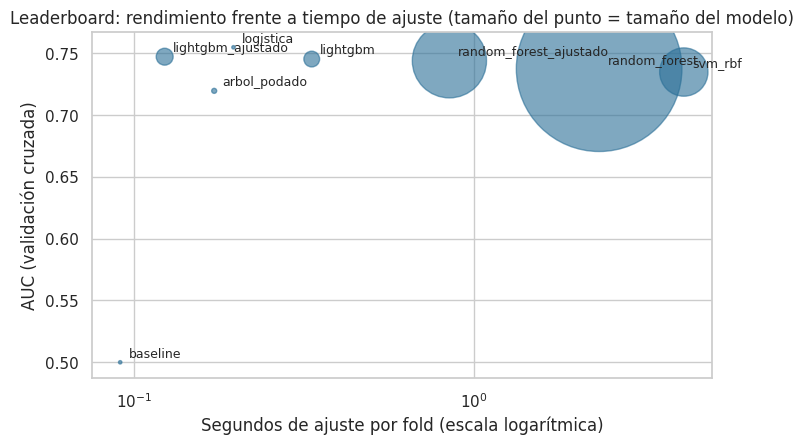

In [ ]:
plt.figure(figsize=(8, 4.5))
plt.scatter(lb["seg_ajuste"], lb["auc_cv_media"], s=lb["tamano_kb"].clip(lower=5) * 1.2, alpha=0.6, color="#2a6f97")
for _, f in lb.iterrows():
    plt.annotate(f["modelo"], (f["seg_ajuste"], f["auc_cv_media"]), textcoords="offset points", xytext=(6, 4), fontsize=9)
plt.xscale("log")
plt.title("Leaderboard: rendimiento frente a tiempo de ajuste (tamaño del punto = tamaño del modelo)")
plt.xlabel("Segundos de ajuste por fold (escala logarítmica)")
plt.ylabel("AUC (validación cruzada)")
plt.show()

## 8. Puntuación global con **nuestros** pesos (ejercicio 3)

> ⚠️ **Propuesta del cuaderno: el equipo debe acordar los pesos con la «voz del cliente» y firmarlos.**

| Criterio | Peso | Justificación |
|---|---|---|
| **Rendimiento** (AUC en validación cruzada) | **0,50** | Cada cancelación no detectada o falsa alarma cuesta dinero (Sprint 7: ≈ 150 € y ≈ 75 €), así que acertar más importa; pero la diferencia entre los mejores modelos es de pocas centésimas de AUC. |
| **Explicabilidad** (1–5) | **0,30** | El gerente no es técnico y quiere poder explicar al personal por qué se avisa de una cancelación; un modelo que no se entiende se usa mal o no se usa. |
| **Coste** (tiempo de ajuste + de predicción + tamaño) | **0,20** | TurisData es un hotel pequeño, sin equipo de datos: un modelo barato de mantener y reentrenar es una ventaja, pero no es lo principal. |

In [ ]:
def ranking(lb_, p):
    """Puntuación global ordenada, SIN el baseline: es el suelo de la comparación, no puede ser campeón."""
    r = puntuacion_global(lb_, p)
    return r[r["modelo"] != "baseline"]

pesos = {"rendimiento": 0.50, "explicabilidad": 0.30, "coste": 0.20}
lb_pond = puntuacion_global(lb, pesos)          # tabla completa (incluye el baseline como referencia)
campeon = ranking(lb, pesos).iloc[0]["modelo"]

assert abs(sum(pesos.values()) - 1) < 1e-9, "Los pesos deben sumar 1"
assert set(pesos) == {"rendimiento", "explicabilidad", "coste"}, "Claves: rendimiento, explicabilidad y coste"
assert campeon in set(lb["modelo"]) and campeon != "baseline", "El campeón debe ser uno de los modelos y no el baseline"
print("Campeón con estos pesos:", campeon)
lb_pond[["modelo", "familia", "auc_cv_media", "auc_cv_desv", "explicabilidad_1a5", "punt_rendimiento",
         "punt_explicabilidad", "punt_coste", "puntuacion_global"]]

Campeón con estos pesos: logistica


,modelo,familia,auc_cv_media,auc_cv_desv,explicabilidad_1a5,punt_rendimiento,punt_explicabilidad,punt_coste,puntuacion_global
0,logistica,lineal,0.7546,0.0136,4,1.000,0.75,1.000,0.925
6,arbol_podado,arbol,0.7194,0.0095,5,0.862,1.00,0.911,0.913
1,lightgbm_ajustado,ensemble_boosting,0.7470,0.0152,2,0.970,0.25,0.724,0.705
2,lightgbm,ensemble_boosting,0.7451,0.0143,2,0.963,0.25,0.689,0.694
3,random_forest_ajustado,ensemble_bagging,0.7437,0.0125,2,0.957,0.25,0.273,0.608
4,random_forest,ensemble_bagging,0.7373,0.0119,2,0.932,0.25,0.000,0.541
7,baseline,referencia,0.5000,0.0000,5,0.000,1.00,0.977,0.495
5,svm_rbf,svm,0.7346,0.0118,1,0.921,0.00,0.093,0.479


### Análisis de sensibilidad de los pesos

¿Cambia el campeón si cambian los pesos? Tres escenarios de ejemplo de la plantilla, **nuestros pesos**, y un barrido de **todas las combinaciones de pesos
con paso 0,1** (66 combinaciones) para ver cuántas veces gana cada modelo.

In [ ]:
escenarios = {"solo rendimiento": {"rendimiento": 0.8, "explicabilidad": 0.1, "coste": 0.1},
              "equilibrado": {"rendimiento": 0.4, "explicabilidad": 0.4, "coste": 0.2},
              "explicabilidad primero": {"rendimiento": 0.2, "explicabilidad": 0.6, "coste": 0.2},
              "nuestros pesos": pesos}
sens = pd.DataFrame({nombre: [ranking(lb, p).iloc[0]["modelo"], ranking(lb, p).iloc[1]["modelo"]]
                     for nombre, p in escenarios.items()},
                    index=["campeón", "segundo"]).T
display(sens)

# Barrido de pesos (paso 0,1): ¿qué modelo gana en cada combinación?
ganadores = []
for r in range(0, 11):
    for e in range(0, 11 - r):
        p = {"rendimiento": r / 10, "explicabilidad": e / 10, "coste": (10 - r - e) / 10}
        ganadores.append({**p, "campeón": ranking(lb, p).iloc[0]["modelo"]})
barrido = pd.DataFrame(ganadores)
resumen_barrido = barrido["campeón"].value_counts().rename("combinaciones_ganadas").to_frame()
resumen_barrido["% de las 66"] = (resumen_barrido["combinaciones_ganadas"] / len(barrido) * 100).round(0)
display(resumen_barrido)
cambia_campeon = sens["campeón"].nunique() > 1
print("¿Cambia el campeón entre los escenarios?", "SÍ" if cambia_campeon else "NO")

,campeón,segundo
solo rendimiento,logistica,arbol_podado
equilibrado,arbol_podado,logistica
explicabilidad primero,arbol_podado,logistica
nuestros pesos,logistica,arbol_podado


,combinaciones_ganadas,% de las 66
campeón,,
logistica,35,53.0
arbol_podado,31,47.0


¿Cambia el campeón entre los escenarios? SÍ


> **Sobre el baseline:** el modelo de referencia no puede ser campeón (no predice nada útil). Aunque con pesos muy centrados en explicabilidad y coste su puntuación
> sería alta, el ranking del campeón se calcula **sin él** (función `ranking`).

### ¿Es estable el campeón frente al ruido de los tiempos?

Los tiempos de ajuste y de predicción dependen de la máquina de Colab y cambian un poco entre ejecuciones. Se simula ese ruido
(multiplicando los tiempos por un factor aleatorio con ±30 % típico, 500 veces) y se mira **cuántas veces sigue ganando el mismo modelo** con nuestros pesos.

In [ ]:
rng = np.random.default_rng(SEMILLA)
gana = []
for _ in range(500):
    lb_r = lb.copy()
    lb_r["seg_ajuste"] = lb_r["seg_ajuste"] * rng.lognormal(0, 0.3, len(lb_r))
    lb_r["ms_pred_1000"] = lb_r["ms_pred_1000"] * rng.lognormal(0, 0.3, len(lb_r))
    gana.append(ranking(lb_r, pesos).iloc[0]["modelo"])
estabilidad_campeon = pd.Series(gana).value_counts(normalize=True)
print("Con ruido en los tiempos, gana cada modelo en este % de las simulaciones:")
print((estabilidad_campeon * 100).round(0).astype(int).astype(str).add(" %").to_string())

Con ruido en los tiempos, gana cada modelo en este % de las simulaciones:
logistica       92 %
arbol_podado     8 %


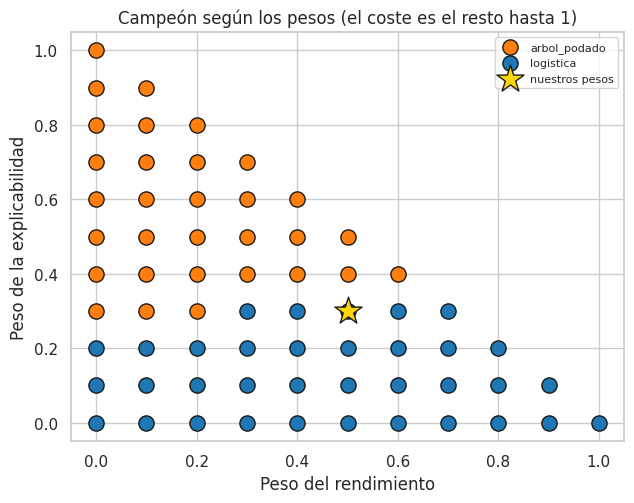

In [ ]:
fig, ax = plt.subplots(figsize=(6.5, 5.2))
colores = {m: c for m, c in zip(barrido["campeón"].unique(), sns.color_palette("tab10", barrido["campeón"].nunique()))}
for m, g in barrido.groupby("campeón"):
    ax.scatter(g["rendimiento"], g["explicabilidad"], s=120, color=colores[m], label=m, edgecolor="k")
ax.scatter([pesos["rendimiento"]], [pesos["explicabilidad"]], marker="*", s=420, color="gold", edgecolor="k", label="nuestros pesos", zorder=5)
ax.set(title="Campeón según los pesos (el coste es el resto hasta 1)", xlabel="Peso del rendimiento", ylabel="Peso de la explicabilidad")
ax.legend(fontsize=8, loc="upper right"); plt.tight_layout(); plt.show()

## 9. Extras con solo train (sin tocar el test)

### 9.1 Catálogo de modelos
Cada entrada reconstruye el pipeline de un modelo (se usa para las comparaciones y para el examen final).

In [ ]:
from sklearn.model_selection import cross_val_score, cross_val_predict   # (no vienen en la celda de herramientas)

def actualizar_test(nombre, valor):
    """Guarda el AUC de test del campeón en el leaderboard (solo debe llamarse UNA vez)."""
    tabla = pd.read_csv(RUTA_CSV)
    tabla.loc[tabla["modelo"] == nombre, "auc_test"] = round(float(valor), 4)
    tabla.to_csv(RUTA_CSV, index=False)
    return tabla

catalogo = {  # cómo reconstruir cada modelo (los ajustados, con los mejores hiperparámetros de las búsquedas)
    "logistica": lambda: hacer_pipe(LogisticRegression(max_iter=1000), escalar=True),
    "arbol_podado": lambda: hacer_pipe(DecisionTreeClassifier(min_samples_leaf=80, random_state=SEMILLA)),
    "random_forest": lambda: hacer_pipe(RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=SEMILLA, n_jobs=2)),
    "lightgbm": lambda: hacer_pipe(lgb.LGBMClassifier(n_estimators=100, learning_rate=0.05, num_leaves=8, random_state=SEMILLA, n_jobs=2, verbose=-1)),
    "svm_rbf": lambda: hacer_pipe(SVC(kernel="rbf", C=1, probability=True, random_state=SEMILLA), escalar=True),
    "random_forest_ajustado": lambda: clone(busq_rf.best_estimator_),
    "lightgbm_ajustado": lambda: clone(busq_lgb.best_estimator_),
}
assert campeon in catalogo, "El campeón no está en el catálogo: añadidlo"
print("Campeón:", campeon, "· está en el catálogo ✔")

Campeón: logistica · está en el catálogo ✔


### 9.2 Comparación con incertidumbre (varias semillas de validación cruzada)

Los 3 mejores por puntuación global se vuelven a medir con **5 particiones distintas** de la validación cruzada (solo train).
Si las diferencias de AUC son menores que la variación entre semillas, **no son una ventaja real**.

In [ ]:
semillas_cv = [42, 7, 123, 2024, 99]
top3 = ranking(lb, pesos).head(3)["modelo"].tolist()
if "logistica" not in top3: top3.append("logistica")
filas = []
for nombre in top3:
    aucs = [cross_val_score(catalogo[nombre](), X_train, y_train, scoring="roc_auc",
                            cv=StratifiedKFold(5, shuffle=True, random_state=s)).mean() for s in semillas_cv]
    filas.append({"modelo": nombre, "auc_medio_5_semillas": np.mean(aucs), "desv_entre_semillas": np.std(aucs),
                  "min": min(aucs), "max": max(aucs)})
incertidumbre = pd.DataFrame(filas).set_index("modelo").round(4)
incertidumbre

,auc_medio_5_semillas,desv_entre_semillas,min,max
modelo,,,,
logistica,0.7533,0.0009,0.7521,0.7546
arbol_podado,0.7198,0.0011,0.7180,0.7215
lightgbm_ajustado,0.7470,0.0015,0.7447,0.7493


### 9.3 Variables más importantes del campeón (explicadas para el gerente)

Se mide con **importancia por permutación** sobre una parte de *train* que el modelo no ha visto (20 % de `X_train` apartado
para validar; **sin usar el test**): cuánto baja el AUC si se desordena una variable.

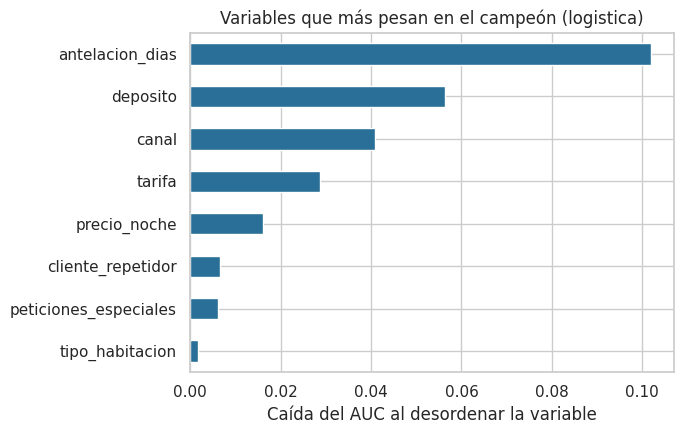

,0
antelacion_dias,0.1019
deposito,0.0563
canal,0.0410
tarifa,0.0287
precio_noche,0.0162
cliente_repetidor,0.0067


In [ ]:
from sklearn.inspection import permutation_importance
X_a, X_v, y_a, y_v = train_test_split(X_train, y_train, test_size=0.2, random_state=SEMILLA, stratify=y_train)
modelo_imp = catalogo[campeon]().fit(X_a, y_a)
pi = permutation_importance(modelo_imp, X_v, y_v, scoring="roc_auc", n_repeats=10, random_state=SEMILLA)
importancias = pd.Series(pi.importances_mean, index=X_train.columns).sort_values(ascending=False)
plt.figure(figsize=(7, 4.5))
importancias.head(8).iloc[::-1].plot(kind="barh", color="#2a6f97")
plt.title(f"Variables que más pesan en el campeón ({campeon})")
plt.xlabel("Caída del AUC al desordenar la variable"); plt.ylabel("")
plt.tight_layout(); plt.show()
importancias.head(6).round(4)

In [ ]:
# Si el campeón es la regresión logística: qué empuja hacia cancelar y qué hacia mantener (odds ratio)
odds = None
if campeon == "logistica":
    pipe_or = catalogo["logistica"]().fit(X_train, y_train)
    odds = pd.Series(np.exp(pipe_or[-1].coef_[0]), index=pipe_or[:-1].get_feature_names_out()).sort_values(ascending=False)
    print("Más riesgo de cancelar (odds ratio > 1; las numéricas, por cada desviación típica):"); display(odds.head(5).round(2))
    print("Menos riesgo de cancelar (odds ratio < 1):"); display(odds.tail(5).round(2))

Más riesgo de cancelar (odds ratio > 1; las numéricas, por cada desviación típica):


,0
num__antelacion_dias,2.14
cat__deposito_sin_deposito,1.87
cat__canal_web_intermediaria,1.62
cat__tarifa_flexible,1.34
num__temporada_alta,1.30


Menos riesgo de cancelar (odds ratio < 1):


,0
cat__tipo_habitacion_estandar,0.78
num__precio_noche,0.71
cat__tarifa_no_reembolsable,0.60
cat__canal_directo,0.54
cat__deposito_total,0.43


### 9.4 IA responsable: AUC y falsas alarmas por canal y por país (solo train)

El **país de origen** es una variable sensible: un modelo que funciona peor para unos países que para otros, o que los marca más, podría tratarlos peor.
Se mide con las predicciones de validación cruzada del campeón (solo *train*).

In [ ]:
from sklearn.model_selection import cross_val_predict
proba_cv_camp = cross_val_predict(catalogo[campeon](), X_train, y_train, cv=cv, method="predict_proba")[:, 1]
aux = X_train.assign(real=y_train.values, proba=proba_cv_camp)
aux["pais_origen"] = aux["pais_origen"].fillna("desconocido")
umbral_ref = float(np.median(proba_cv_camp))   # marcamos la mitad de reservas con más riesgo: mismo criterio para todos los grupos

def tabla_grupo(col):
    filas = []
    for g, d in aux.groupby(col):
        auc_g = roc_auc_score(d["real"], d["proba"]) if d["real"].nunique() == 2 else np.nan
        marcadas = (d["proba"] >= umbral_ref)
        filas.append({col: g, "reservas": len(d), "tasa_cancelación_real": d["real"].mean(), "AUC": auc_g,
                      "% marcadas como riesgo": marcadas.mean(),
                      "tasa falsas alarmas": (marcadas & (d["real"] == 0)).sum() / max((d["real"] == 0).sum(), 1)})
    return pd.DataFrame(filas).set_index(col).round(3).sort_values("AUC")

por_canal, por_pais = tabla_grupo("canal"), tabla_grupo("pais_origen")
display(por_canal); display(por_pais)
brecha_auc_pais = por_pais["AUC"].max() - por_pais["AUC"].min()
brecha_fp_pais = por_pais["tasa falsas alarmas"].max() - por_pais["tasa falsas alarmas"].min()
brecha_auc_canal = por_canal["AUC"].max() - por_canal["AUC"].min()
print(f"Brecha de AUC entre países: {brecha_auc_pais:.3f} · entre canales: {brecha_auc_canal:.3f} · "
      f"brecha de falsas alarmas entre países: {brecha_fp_pais:.3f}")

,reservas,tasa_cancelación_real,AUC,% marcadas como riesgo,tasa falsas alarmas
canal,,,,,
empresa,261,0.429,0.695,0.444,0.315
web_intermediaria,2413,0.535,0.737,0.643,0.469
directo,1162,0.325,0.750,0.259,0.168
agencia,964,0.437,0.755,0.448,0.287


,reservas,tasa_cancelación_real,AUC,% marcadas como riesgo,tasa falsas alarmas
pais_origen,,,,,
desconocido,108,0.333,0.693,0.509,0.417
UK,1194,0.478,0.739,0.534,0.371
NL,290,0.448,0.749,0.462,0.300
otros,475,0.461,0.750,0.501,0.344
Nordicos,331,0.453,0.751,0.502,0.326
ES,1314,0.453,0.760,0.470,0.303
DE,676,0.453,0.761,0.496,0.324
IT,229,0.485,0.781,0.528,0.314
FR,183,0.464,0.810,0.525,0.306


Brecha de AUC entre países: 0.117 · entre canales: 0.060 · brecha de falsas alarmas entre países: 0.117


## 10. El examen final: solo el campeón, una vez (ejercicio 4)

El campeón (elegido con `puntuacion_global` y **nuestros pesos**) se reconstruye, se ajusta con **todo `X_train`** y se evalúa
en `X_test` **una sola vez**. La columna `auc_test` del leaderboard tendrá valor en **una única fila**.

In [ ]:
campeon_pipe = catalogo[campeon]().fit(X_train, y_train)
auc_test_campeon = roc_auc_score(y_test, campeon_pipe.predict_proba(X_test)[:, 1])
lb_final = actualizar_test(campeon, auc_test_campeon)

assert 0.65 < auc_test_campeon < 0.85, "El AUC de test del campeón debería estar entre 0,65 y 0,85"
assert lb_final["auc_test"].notna().sum() == 1, "Solo el campeón debe tener AUC de test"
print(f"Campeón: {campeon} · AUC en validación cruzada {lb_pond.set_index('modelo').loc[campeon, 'auc_cv_media']:.3f} · AUC en test {auc_test_campeon:.3f}")
lb_final

Campeón: logistica · AUC en validación cruzada 0.755 · AUC en test 0.762


,modelo,familia,auc_cv_media,auc_cv_desv,ap_cv_media,seg_ajuste,ms_pred_1000,tamano_kb,explicabilidad_1a5,notas,auc_test
0,logistica,lineal,0.7546,0.0136,0.7183,0.196,28.8,4.2,4,Coeficientes legibles (odds ratio),0.7623
1,lightgbm_ajustado,ensemble_boosting,0.7470,0.0152,0.7094,0.123,19.2,123.5,2,Mejor de la búsqueda aleatoria (solo train),NaN
2,lightgbm,ensemble_boosting,0.7451,0.0143,0.7062,0.333,26.9,107.2,2,Árboles en serie; rápido; caja negra,NaN
3,random_forest_ajustado,ensemble_bagging,0.7437,0.0125,0.7009,0.846,54.6,2377.9,2,"Mejor de la rejilla (GridSearchCV, solo train)",NaN
4,random_forest,ensemble_bagging,0.7373,0.0119,0.6916,2.332,91.2,11847.0,2,Muchos árboles votan; caja negra,NaN
5,svm_rbf,svm,0.7346,0.0118,0.6883,4.138,278.5,1008.8,1,Frontera curva; lenta con muchas filas,NaN
6,arbol_podado,arbol,0.7194,0.0095,0.6668,0.172,30.7,11.0,5,Se lee como reglas si/entonces,NaN
7,baseline,referencia,0.5000,0.0000,0.4590,0.091,49.6,3.2,5,Predice siempre la proporción de cada clase,NaN


## 11. Cifras para la *model card* y descarga del leaderboard

Esta celda reúne las cifras que aparecen en `model_card.md` y en el README (`cifras_reto_S08.json`).
Después se descarga `leaderboard_S08.csv` (Colab borra los ficheros al cerrar la sesión).

In [ ]:
import json
fila_c = lb_pond.set_index("modelo").loc[campeon]
seg_modelo = lb_pond.set_index("modelo")
cifras = {
    "n_modelos": int(len(lb_final)), "n_familias": int(lb_final["familia"].nunique()),
    "familias": sorted(lb_final["familia"].unique().tolist()),
    "pesos": pesos, "campeon": campeon, "campeon_familia": fila_c["familia"],
    "campeon_auc_cv": float(fila_c["auc_cv_media"]), "campeon_auc_cv_desv": float(fila_c["auc_cv_desv"]),
    "campeon_ap_cv": float(fila_c["ap_cv_media"]), "campeon_explicabilidad": int(fila_c["explicabilidad_1a5"]),
    "campeon_puntuacion": float(fila_c["puntuacion_global"]),
    "campeon_seg_ajuste": float(fila_c["seg_ajuste"]), "campeon_ms_pred_1000": float(fila_c["ms_pred_1000"]),
    "campeon_tamano_kb": float(fila_c["tamano_kb"]),
    "auc_test_campeon": round(float(auc_test_campeon), 4),
    "segundo": ranking(lb, pesos).iloc[1]["modelo"], "segundo_puntuacion": float(ranking(lb, pesos).iloc[1]["puntuacion_global"]),
    "segundo_auc_cv": float(ranking(lb, pesos).iloc[1]["auc_cv_media"]),
    "estabilidad_campeon_timing": estabilidad_campeon.round(3).to_dict(),
    "mejor_auc_cv_modelo": lb_pond.sort_values("auc_cv_media", ascending=False).iloc[0]["modelo"],
    "mejor_auc_cv": float(lb_pond["auc_cv_media"].max()),
    "cambia_campeon_escenarios": bool(cambia_campeon),
    "campeones_escenarios": sens["campeón"].to_dict(),
    "barrido_victorias": resumen_barrido["combinaciones_ganadas"].to_dict(),
    "busq_rf_best_auc": float(busq_rf.best_score_), "busq_rf_params": {k: (v if v is not None else "None") for k, v in busq_rf.best_params_.items()},
    "busq_rf_seg": round(seg_rf, 1), "busq_lgb_best_auc": float(busq_lgb.best_score_),
    "busq_lgb_params": {k: (round(v, 4) if isinstance(v, float) else int(v)) for k, v in busq_lgb.best_params_.items()},
    "busq_lgb_seg": round(seg_lgb, 1),
    "odds_mas_riesgo": (odds.head(5).round(3).to_dict() if odds is not None else {}),
    "odds_menos_riesgo": (odds.tail(5).round(3).to_dict() if odds is not None else {}),
    "importancias_top": importancias.head(5).round(4).to_dict(),
    "incertidumbre": incertidumbre.round(4).to_dict(orient="index"),
    "brecha_auc_pais": float(brecha_auc_pais), "brecha_auc_canal": float(brecha_auc_canal), "brecha_fp_pais": float(brecha_fp_pais),
    "auc_pais_min": [por_pais["AUC"].idxmin(), float(por_pais["AUC"].min())], "auc_pais_max": [por_pais["AUC"].idxmax(), float(por_pais["AUC"].max())],
    "auc_canal_min": [por_canal["AUC"].idxmin(), float(por_canal["AUC"].min())], "auc_canal_max": [por_canal["AUC"].idxmax(), float(por_canal["AUC"].max())],
    "fp_pais_max": [por_pais["tasa falsas alarmas"].idxmax(), float(por_pais["tasa falsas alarmas"].max())],
    "fp_pais_min": [por_pais["tasa falsas alarmas"].idxmin(), float(por_pais["tasa falsas alarmas"].min())],
}
with open("cifras_reto_S08.json", "w", encoding="utf-8") as f:
    json.dump(cifras, f, ensure_ascii=False, indent=2, default=str)
print(json.dumps(cifras, ensure_ascii=False, indent=1, default=str)[:3500])

{
 "n_modelos": 8,
 "n_familias": 6,
 "familias": [
  "arbol",
  "ensemble_bagging",
  "ensemble_boosting",
  "lineal",
  "referencia",
  "svm"
 ],
 "pesos": {
  "rendimiento": 0.5,
  "explicabilidad": 0.3,
  "coste": 0.2
 },
 "campeon": "logistica",
 "campeon_familia": "lineal",
 "campeon_auc_cv": 0.7546,
 "campeon_auc_cv_desv": 0.0136,
 "campeon_ap_cv": 0.7183,
 "campeon_explicabilidad": 4,
 "campeon_puntuacion": 0.925,
 "campeon_seg_ajuste": 0.196,
 "campeon_ms_pred_1000": 28.8,
 "campeon_tamano_kb": 4.2,
 "auc_test_campeon": 0.7623,
 "segundo": "arbol_podado",
 "segundo_puntuacion": 0.913,
 "segundo_auc_cv": 0.7194,
 "estabilidad_campeon_timing": {
  "logistica": 0.922,
  "arbol_podado": 0.078
 },
 "mejor_auc_cv_modelo": "logistica",
 "mejor_auc_cv": 0.7546,
 "cambia_campeon_escenarios": true,
 "campeones_escenarios": {
  "solo rendimiento": "logistica",
  "equilibrado": "arbol_podado",
  "explicabilidad primero": "arbol_podado",
  "nuestros pesos": "logistica"
 },
 "barrido_victor

In [ ]:
# Descargar leaderboard_S08.csv (en Colab). Fuera de Colab, el fichero está en la carpeta del cuaderno.
try:
    from google.colab import files
    files.download(RUTA_CSV)
except Exception as e:
    print("Fuera de Colab: el fichero", RUTA_CSV, "está en la carpeta actual.")
print(open(RUTA_CSV).read()[:600])

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

modelo,familia,auc_cv_media,auc_cv_desv,ap_cv_media,seg_ajuste,ms_pred_1000,tamano_kb,explicabilidad_1a5,notas,auc_test
logistica,lineal,0.7546,0.0136,0.7183,0.196,28.8,4.2,4,Coeficientes legibles (odds ratio),0.7623
lightgbm_ajustado,ensemble_boosting,0.747,0.0152,0.7094,0.123,19.2,123.5,2,Mejor de la búsqueda aleatoria (solo train),
lightgbm,ensemble_boosting,0.7451,0.0143,0.7062,0.333,26.9,107.2,2,Árboles en serie; rápido; caja negra,
random_forest_ajustado,ensemble_bagging,0.7437,0.0125,0.7009,0.846,54.6,2377.9,2,"Mejor de la rejilla (GridSearchCV, solo train)",
random_forest,ensemble_bagg


## Para reflexionar

1. ¿Por qué se miden todos los modelos con los **mismos folds**, las mismas variables y la misma métrica?
2. Si el campeón por AUC y el campeón por puntuación global son distintos, ¿a quién y cómo se lo explicamos?
3. ¿Qué pasaría con la nota del campeón si hubiéramos elegido el modelo mirando el test?
4. ¿Qué falta en el leaderboard que el cliente querría saber (mantenimiento, deriva, riesgo de sesgo)?